# ⚽ Manchester City vs Queens Park Rangers
## Football Match Intelligence

**Premier League — 13 May 2012**

A data-driven analysis of Manchester City's dramatic 3–2 comeback against
Queens Park Rangers at the Etihad Stadium.

### Project Objectives

- Analyze match statistics and event data
- Examine possession and attacking pressure
- Visualize the match timeline and score evolution
- Analyze the late-game comeback
- Derive meaningful football insights from the available data

### Tools Used

Python • Pandas • NumPy • Matplotlib • Plotly • mplsoccer

## 1. Environment Setup

The analysis uses Python-based data analysis and visualization libraries to
process match data and create football analytics visualizations.

In [1]:
!pip install pandas numpy matplotlib mplsoccer pillow plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 6.4 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 5.0 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/9.7 MB 4.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.7 MB 4.4 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 3.5 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 3.5 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.7 MB 3.0 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.7 MB 2.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.7 MB 2.5 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 2.6 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.7 MB 2.6 MB/s eta 0:00:02
   --------------------------- ------------ 6.6/9.7 MB 2.5 MB/s eta 0:00:02
   ----------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from mplsoccer import Pitch, VerticalPitch

import plotly.express as px

print("Libraries loaded successfully! ⚽")

Libraries loaded successfully! ⚽


## 2. Match Information

Basic match details used throughout the analysis.

In [3]:
MATCH_INFO = {
    "home_team": "Manchester City",
    "away_team": "Queens Park Rangers",
    "home_score": 3,
    "away_score": 2,
    "competition": "Premier League",
    "season": "2011/12",
    "date": "13 May 2012",
    "venue": "Etihad Stadium"
}

MATCH_INFO

{'home_team': 'Manchester City',
 'away_team': 'Queens Park Rangers',
 'home_score': 3,
 'away_score': 2,
 'competition': 'Premier League',
 'season': '2011/12',
 'date': '13 May 2012',
 'venue': 'Etihad Stadium'}

## 3. Match Statistics

A comparison of key performance indicators between Manchester City and
Queens Park Rangers, including possession, shooting, passing and discipline.

In [4]:
match_stats = pd.DataFrame({
    "Metric": [
        "Possession",
        "Shots",
        "Shots on Target",
        "Corners",
        "Passes",
        "Pass Accuracy",
        "Yellow Cards",
        "Red Cards"
    ],
    
    "Manchester City": [
        81.3,
        44,
        15,
        19,
        710,
        91.7,
        1,
        0
    ],
    
    "Queens Park Rangers": [
        18.7,
        3,
        3,
        0,
        175,
        49.7,
        1,
        1
    ]
})

match_stats

,Metric,Manchester City,Queens Park Rangers
0,Possession,81.3,18.7
1,Shots,44.0,3.0
2,Shots on Target,15.0,3.0
3,Corners,19.0,0.0
4,Passes,710.0,175.0
5,Pass Accuracy,91.7,49.7
6,Yellow Cards,1.0,1.0
7,Red Cards,0.0,1.0


In [5]:
events = pd.DataFrame({
    "minute": [39, 48, 55, 66, 92, 94],

    "team": [
        "Manchester City",
        "Queens Park Rangers",
        "Queens Park Rangers",
        "Queens Park Rangers",
        "Manchester City",
        "Manchester City"
    ],

    "player": [
        "Pablo Zabaleta",
        "Djibril Cissé",
        "Joey Barton",
        "Jamie Mackie",
        "Edin Džeko",
        "Sergio Agüero"
    ],

    "event": [
        "Goal",
        "Goal",
        "Red Card",
        "Goal",
        "Goal",
        "Goal"
    ]
})

events

,minute,team,player,event
0,39,Manchester City,Pablo Zabaleta,Goal
1,48,Queens Park Rangers,Djibril Cissé,Goal
2,55,Queens Park Rangers,Joey Barton,Red Card
3,66,Queens Park Rangers,Jamie Mackie,Goal
4,92,Manchester City,Edin Džeko,Goal
5,94,Manchester City,Sergio Agüero,Goal


In [6]:
city_score = 0
qpr_score = 0

score_states = []

for _, row in events.iterrows():

    if row["event"] == "Goal":
        if row["team"] == "Manchester City":
            city_score += 1
        else:
            qpr_score += 1

    score_states.append(f"{city_score}-{qpr_score}")

events["score"] = score_states

events

,minute,team,player,event,score
0,39,Manchester City,Pablo Zabaleta,Goal,1-0
1,48,Queens Park Rangers,Djibril Cissé,Goal,1-1
2,55,Queens Park Rangers,Joey Barton,Red Card,1-1
3,66,Queens Park Rangers,Jamie Mackie,Goal,1-2
4,92,Manchester City,Edin Džeko,Goal,2-2
5,94,Manchester City,Sergio Agüero,Goal,3-2


In [8]:
for _, row in events.iterrows():

    if row["event"] == "Goal":

        print(
            f"{row['minute']}'  |  "
            f"{row['player']}  |  "
            f"{row['team']}  |  "
            f"Score: {row['score']}"
        )

39'  |  Pablo Zabaleta  |  Manchester City  |  Score: 1-0
48'  |  Djibril Cissé  |  Queens Park Rangers  |  Score: 1-1
66'  |  Jamie Mackie  |  Queens Park Rangers  |  Score: 1-2
92'  |  Edin Džeko  |  Manchester City  |  Score: 2-2
94'  |  Sergio Agüero  |  Manchester City  |  Score: 3-2


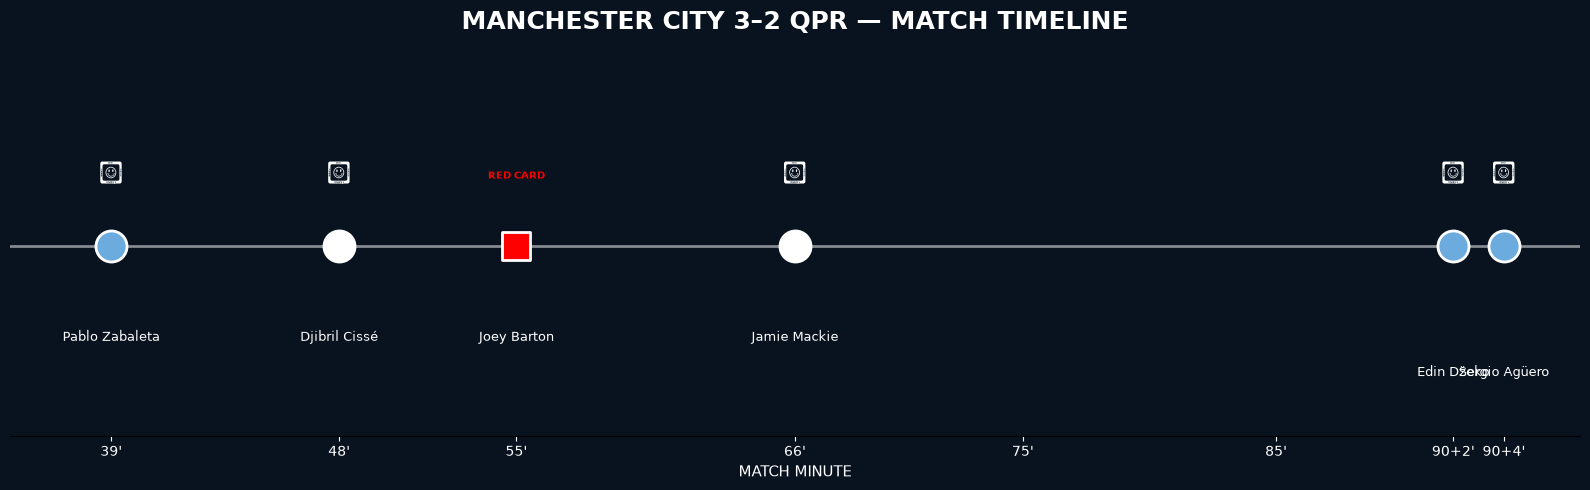

In [10]:
# ============================================
# STEP 6 — MATCH EVENT TIMELINE
# ============================================

fig, ax = plt.subplots(figsize=(16, 5))

# Background
fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Team colors
CITY_COLOR = "#6CABDD"
QPR_COLOR = "#FFFFFF"

# Timeline line
ax.axhline(
    y=0,
    color="white",
    linewidth=2,
    alpha=0.5
)

# Plot every event
for _, row in events.iterrows():

    # Choose team color
    if row["team"] == "Manchester City":
        color = CITY_COLOR
    else:
        color = QPR_COLOR

    # -------------------------
    # GOAL
    # -------------------------
    if row["event"] == "Goal":

        ax.scatter(
            row["minute"],
            0,
            s=500,
            color=color,
            edgecolor="white",
            linewidth=2,
            zorder=5
        )

        # Football marker
        ax.text(
            row["minute"],
            0.25,
            "⚽",
            fontsize=16,
            ha="center",
            color="white"
        )

        # Put stoppage-time labels slightly lower
        if row["minute"] >= 90:
            label_y = -0.48
        else:
            label_y = -0.35

        ax.text(
            row["minute"],
            label_y,
            row["player"],
            fontsize=9,
            ha="center",
            color="white"
        )

    # -------------------------
    # RED CARD
    # -------------------------
    elif row["event"] == "Red Card":

        ax.scatter(
            row["minute"],
            0,
            s=400,
            color="red",
            edgecolor="white",
            linewidth=2,
            marker="s",
            zorder=5
        )

        ax.text(
            row["minute"],
            0.25,
            "RED CARD",
            fontsize=7,
            fontweight="bold",
            ha="center",
            color="red"
        )

        ax.text(
            row["minute"],
            -0.35,
            row["player"],
            fontsize=9,
            ha="center",
            color="white"
        )


# ============================================
# AXIS SETTINGS
# ============================================

ax.set_xlim(35, 97)
ax.set_ylim(-0.7, 0.7)

ax.set_xticks([
    39,
    48,
    55,
    66,
    75,
    85,
    92,
    94
])

ax.set_xticklabels([
    "39'",
    "48'",
    "55'",
    "66'",
    "75'",
    "85'",
    "90+2'",
    "90+4'"
])

ax.set_xlabel(
    "MATCH MINUTE",
    color="white",
    fontsize=11
)

ax.set_title(
    "MANCHESTER CITY 3–2 QPR — MATCH TIMELINE",
    color="white",
    fontsize=18,
    fontweight="bold",
    pad=20
)

# Tick colors
ax.tick_params(
    axis="x",
    colors="white"
)

ax.tick_params(
    axis="y",
    left=False,
    labelleft=False
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()

plt.show()

In [11]:
# ============================================
# SCORE STATE AFTER EACH GOAL
# ============================================

for _, row in events.iterrows():

    if row["event"] == "Goal":

        print(
            f"{row['minute']}'  |  "
            f"{row['player']}  |  "
            f"{row['team']}  |  "
            f"Score: {row['score']}"
        )

39'  |  Pablo Zabaleta  |  Manchester City  |  Score: 1-0
48'  |  Djibril Cissé  |  Queens Park Rangers  |  Score: 1-1
66'  |  Jamie Mackie  |  Queens Park Rangers  |  Score: 1-2
92'  |  Edin Džeko  |  Manchester City  |  Score: 2-2
94'  |  Sergio Agüero  |  Manchester City  |  Score: 3-2


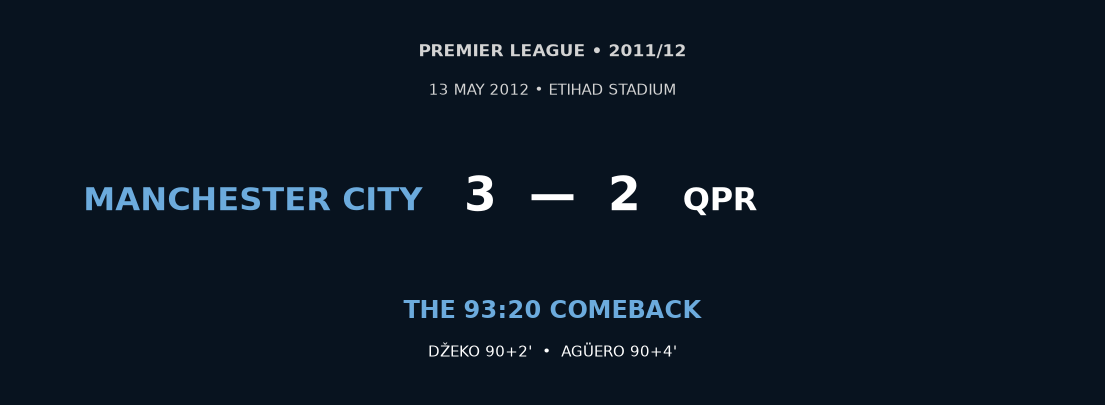

In [12]:
# ============================================
# STEP 7 — MATCH HEADER
# ============================================

fig, ax = plt.subplots(figsize=(14, 5))

# Background
fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Competition
ax.text(
    0.5,
    0.88,
    "PREMIER LEAGUE • 2011/12",
    fontsize=12,
    color="lightgray",
    ha="center",
    fontweight="bold"
)

# Date and venue
ax.text(
    0.5,
    0.78,
    "13 MAY 2012 • ETIHAD STADIUM",
    fontsize=11,
    color="lightgray",
    ha="center"
)

# Manchester City
ax.text(
    0.38,
    0.48,
    "MANCHESTER CITY",
    fontsize=23,
    color=CITY_COLOR,
    fontweight="bold",
    ha="right"
)

# Score
ax.text(
    0.5,
    0.48,
    "3  —  2",
    fontsize=34,
    color="white",
    fontweight="bold",
    ha="center"
)

# QPR
ax.text(
    0.62,
    0.48,
    "QPR",
    fontsize=23,
    color=QPR_COLOR,
    fontweight="bold",
    ha="left"
)

# Main story
ax.text(
    0.5,
    0.20,
    "THE 93:20 COMEBACK",
    fontsize=17,
    color=CITY_COLOR,
    fontweight="bold",
    ha="center"
)

# Final goals
ax.text(
    0.5,
    0.10,
    "DŽEKO 90+2'  •  AGÜERO 90+4'",
    fontsize=11,
    color="white",
    ha="center"
)

ax.axis("off")

plt.show()

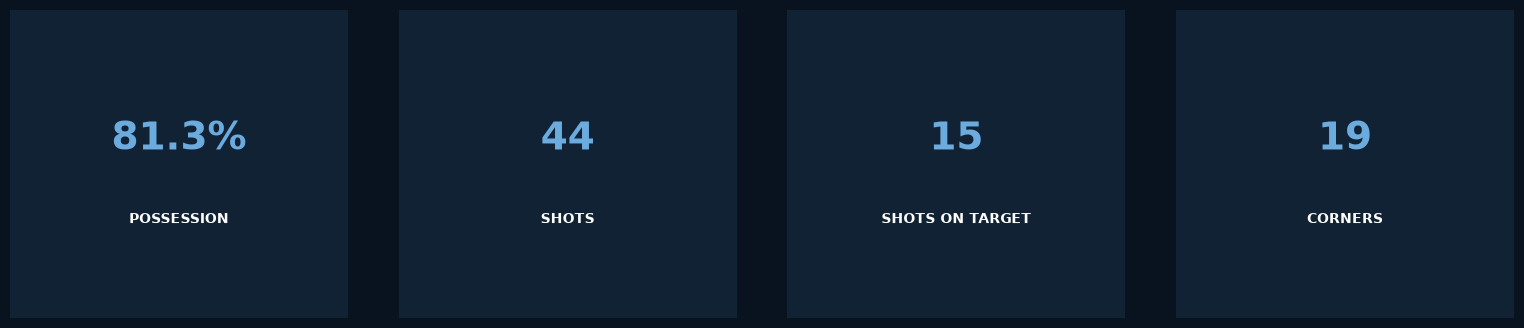

In [13]:
# ============================================
# STEP 8 — MATCH STATISTICS CARDS
# ============================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

fig.patch.set_facecolor("#08131F")

# Statistics we want to display
cards = [
    ("81.3%", "POSSESSION"),
    ("44", "SHOTS"),
    ("15", "SHOTS ON TARGET"),
    ("19", "CORNERS")
]

for ax, (value, label) in zip(axes, cards):

    # Card background
    ax.set_facecolor("#102233")

    # Value
    ax.text(
        0.5,
        0.58,
        value,
        fontsize=28,
        fontweight="bold",
        color=CITY_COLOR,
        ha="center",
        va="center"
    )

    # Label
    ax.text(
        0.5,
        0.32,
        label,
        fontsize=10,
        fontweight="bold",
        color="white",
        ha="center",
        va="center"
    )

    # Remove axes
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

plt.subplots_adjust(
    left=0.03,
    right=0.97,
    wspace=0.15
)

plt.show()

In [14]:
# ============================================
# STEP 9 — CITY VS QPR STATISTICS
# ============================================

comparison = match_stats.copy()

comparison

,Metric,Manchester City,Queens Park Rangers
0,Possession,81.3,18.7
1,Shots,44.0,3.0
2,Shots on Target,15.0,3.0
3,Corners,19.0,0.0
4,Passes,710.0,175.0
5,Pass Accuracy,91.7,49.7
6,Yellow Cards,1.0,1.0
7,Red Cards,0.0,1.0


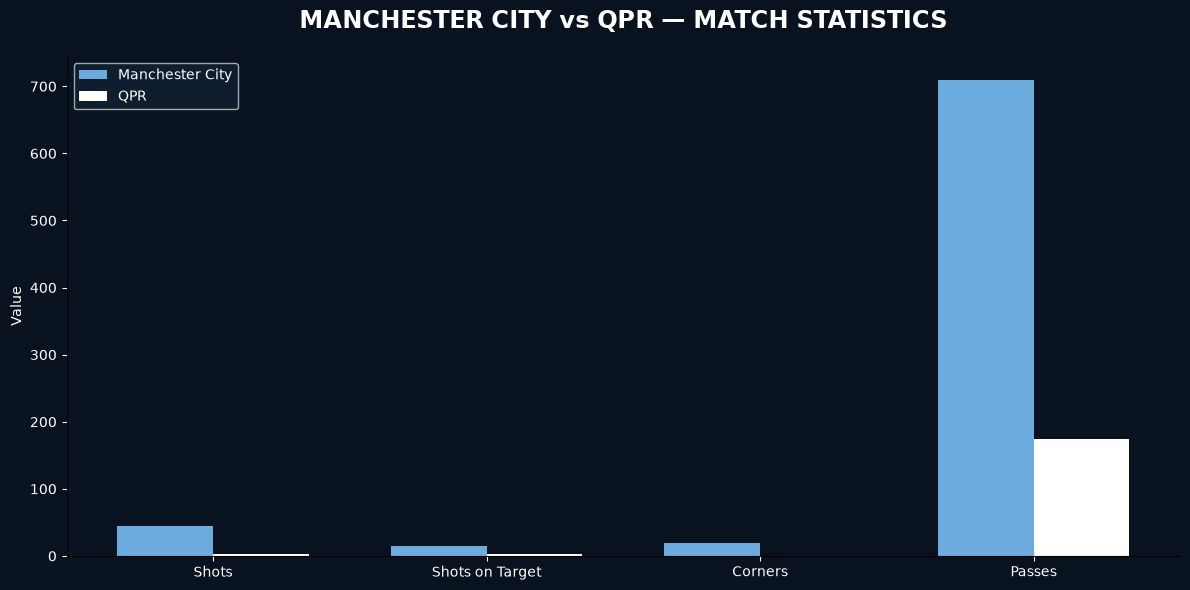

In [15]:
# ============================================
# STEP 9.1 — STATISTICS COMPARISON
# ============================================

fig, ax = plt.subplots(figsize=(12, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Select numerical statistics
metrics = [
    "Shots",
    "Shots on Target",
    "Corners",
    "Passes"
]

city_values = [
    match_stats.loc[match_stats["Metric"] == metric, "Manchester City"].iloc[0]
    for metric in metrics
]

qpr_values = [
    match_stats.loc[match_stats["Metric"] == metric, "Queens Park Rangers"].iloc[0]
    for metric in metrics
]

x = np.arange(len(metrics))
width = 0.35

# Bars
ax.bar(
    x - width / 2,
    city_values,
    width,
    label="Manchester City",
    color=CITY_COLOR
)

ax.bar(
    x + width / 2,
    qpr_values,
    width,
    label="QPR",
    color="#FFFFFF"
)

# Labels
ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_title(
    "MANCHESTER CITY vs QPR — MATCH STATISTICS",
    color="white",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel(
    "Value",
    color="white"
)

ax.tick_params(
    colors="white"
)

ax.legend(
    facecolor="#102233",
    labelcolor="white"
)

# Remove borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()

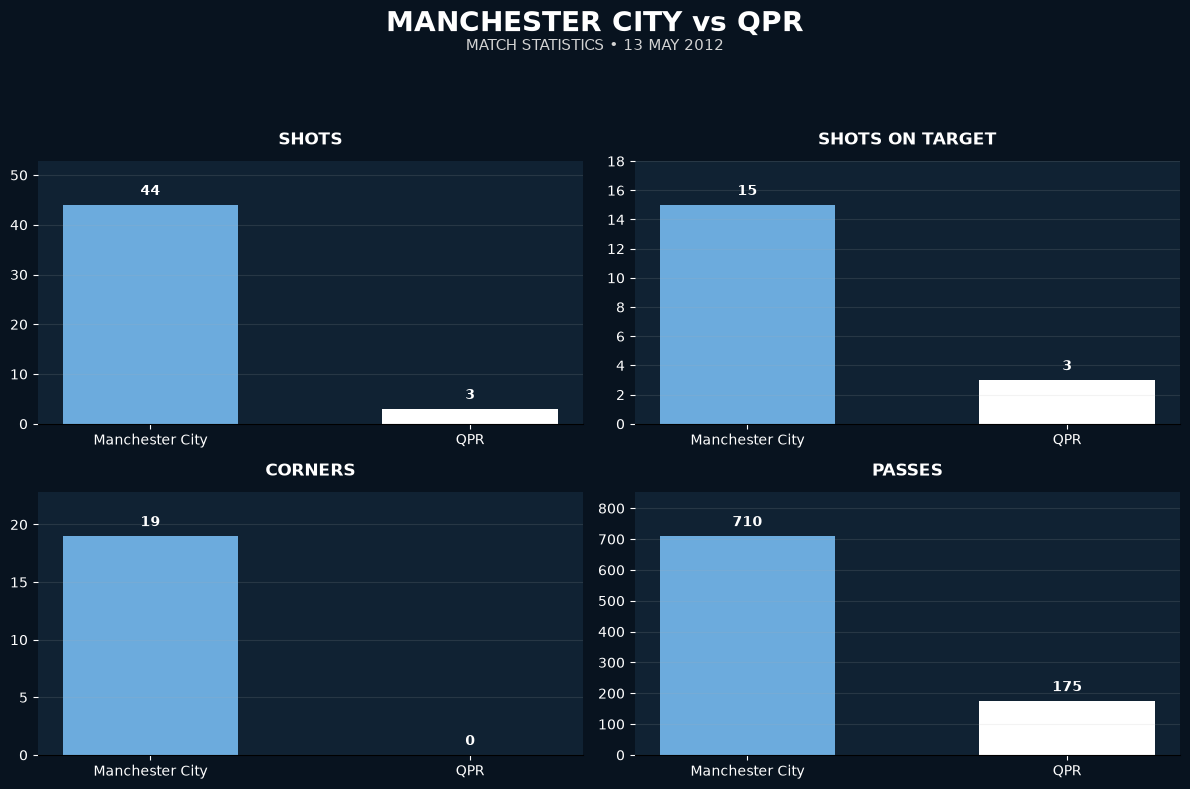

In [16]:
# ============================================
# STEP 9.2 — IMPROVED TEAM COMPARISON
# ============================================

metrics = [
    "Shots",
    "Shots on Target",
    "Corners",
    "Passes"
]

city_values = [
    match_stats.loc[
        match_stats["Metric"] == metric,
        "Manchester City"
    ].iloc[0]
    for metric in metrics
]

qpr_values = [
    match_stats.loc[
        match_stats["Metric"] == metric,
        "Queens Park Rangers"
    ].iloc[0]
    for metric in metrics
]


# Create 2 x 2 layout
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

fig.patch.set_facecolor("#08131F")


for ax, metric, city, qpr in zip(
    axes.flatten(),
    metrics,
    city_values,
    qpr_values
):

    ax.set_facecolor("#102233")

    # Bars
    bars = ax.bar(
        ["Manchester City", "QPR"],
        [city, qpr],
        color=[CITY_COLOR, QPR_COLOR],
        width=0.55
    )

    # Add values above bars
    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + max(city, qpr) * 0.03,
            f"{height:g}",
            ha="center",
            va="bottom",
            color="white",
            fontweight="bold"
        )

    # Metric title
    ax.set_title(
        metric.upper(),
        color="white",
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    # Axis formatting
    ax.tick_params(
        colors="white"
    )

    ax.set_ylim(
        0,
        max(city, qpr) * 1.2
    )

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.15
    )


fig.suptitle(
    "MANCHESTER CITY vs QPR",
    color="white",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.93,
    "MATCH STATISTICS • 13 MAY 2012",
    ha="center",
    color="lightgray",
    fontsize=11
)

plt.tight_layout(
    rect=[0, 0, 1, 0.90]
)

plt.show()

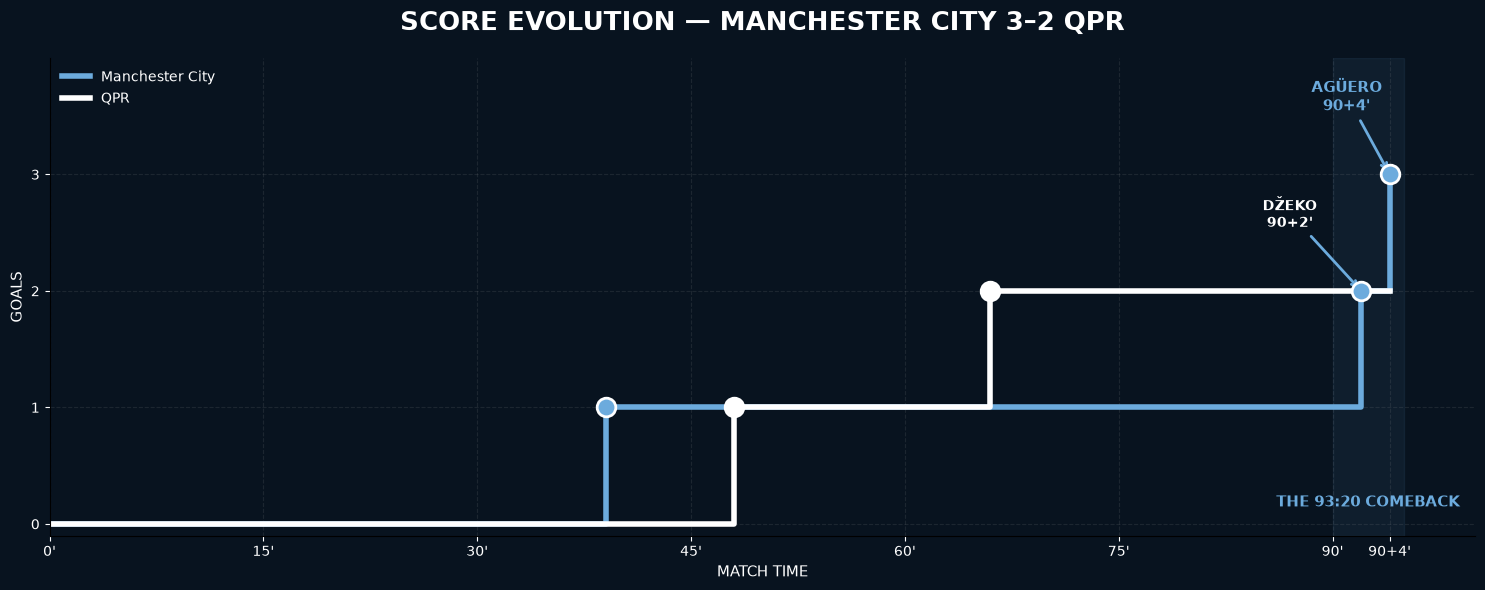

In [17]:
# ============================================
# STEP 10 — SCORE EVOLUTION
# ============================================

# Match minutes
minutes = [0, 39, 48, 66, 92, 94]

# Manchester City score after each event
city_scores = [0, 1, 1, 1, 2, 3]

# QPR score after each event
qpr_scores = [0, 0, 1, 2, 2, 2]


# Create figure
fig, ax = plt.subplots(figsize=(15, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")


# ============================================
# SCORE LINES
# ============================================

ax.step(
    minutes,
    city_scores,
    where="post",
    color=CITY_COLOR,
    linewidth=4,
    label="Manchester City"
)

ax.step(
    minutes,
    qpr_scores,
    where="post",
    color="#FFFFFF",
    linewidth=4,
    label="QPR"
)


# ============================================
# GOAL MARKERS
# ============================================

goal_events = events[events["event"] == "Goal"]

for _, row in goal_events.iterrows():

    minute = row["minute"]

    if row["team"] == "Manchester City":
        score = row["score"].split("-")[0]
        y = int(score)
        color = CITY_COLOR
    else:
        score = row["score"].split("-")[1]
        y = int(score)
        color = "#FFFFFF"

    ax.scatter(
        minute,
        y,
        s=180,
        color=color,
        edgecolor="white",
        linewidth=2,
        zorder=5
    )


# ============================================
# IMPORTANT GOAL LABELS
# ============================================

ax.annotate(
    "DŽEKO\n90+2'",
    xy=(92, 2),
    xytext=(87, 2.55),
    color="white",
    fontsize=10,
    fontweight="bold",
    ha="center",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=2
    )
)

ax.annotate(
    "AGÜERO\n90+4'",
    xy=(94, 3),
    xytext=(91, 3.55),
    color=CITY_COLOR,
    fontsize=11,
    fontweight="bold",
    ha="center",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=2
    )
)


# ============================================
# 93:20 HIGHLIGHT
# ============================================

ax.axvspan(
    90,
    95,
    color=CITY_COLOR,
    alpha=0.08
)

ax.text(
    92.5,
    0.15,
    "THE 93:20 COMEBACK",
    color=CITY_COLOR,
    fontsize=11,
    fontweight="bold",
    ha="center"
)


# ============================================
# AXIS
# ============================================

ax.set_xlim(0, 100)

ax.set_ylim(-0.1, 4)

ax.set_xticks([
    0,
    15,
    30,
    45,
    60,
    75,
    90,
    94
])

ax.set_xticklabels([
    "0'",
    "15'",
    "30'",
    "45'",
    "60'",
    "75'",
    "90'",
    "90+4'"
])


ax.set_yticks([
    0,
    1,
    2,
    3
])

ax.set_yticklabels([
    "0",
    "1",
    "2",
    "3"
])


# ============================================
# TITLE
# ============================================

ax.set_title(
    "SCORE EVOLUTION — MANCHESTER CITY 3–2 QPR",
    color="white",
    fontsize=19,
    fontweight="bold",
    pad=20
)


ax.set_xlabel(
    "MATCH TIME",
    color="white",
    fontsize=11
)

ax.set_ylabel(
    "GOALS",
    color="white",
    fontsize=11
)


# ============================================
# FORMATTING
# ============================================

ax.tick_params(
    colors="white"
)

ax.grid(
    alpha=0.12,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    facecolor="#102233",
    labelcolor="white",
    frameon=False
)

plt.tight_layout()

plt.show()

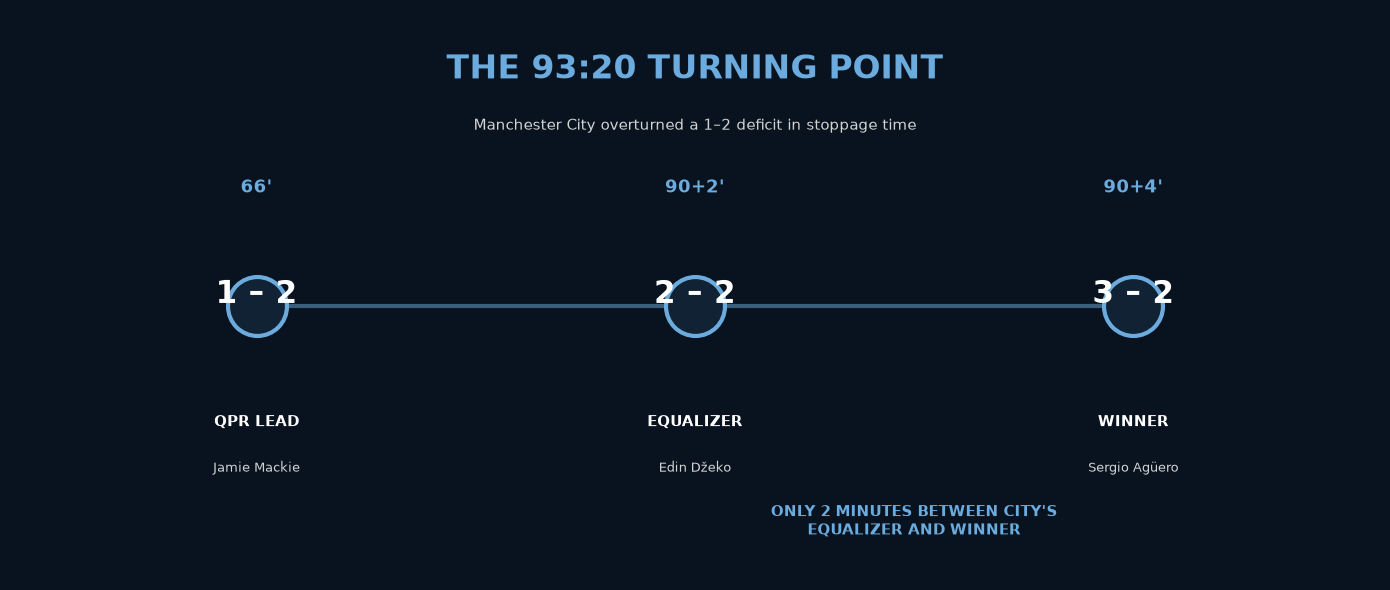

In [18]:
# ============================================
# STEP 11 — 93:20 TURNING POINT
# ============================================

fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# --------------------------------------------
# TITLE
# --------------------------------------------

ax.text(
    0.5,
    0.88,
    "THE 93:20 TURNING POINT",
    fontsize=24,
    fontweight="bold",
    color=CITY_COLOR,
    ha="center"
)

ax.text(
    0.5,
    0.79,
    "Manchester City overturned a 1–2 deficit in stoppage time",
    fontsize=11,
    color="lightgray",
    ha="center"
)


# --------------------------------------------
# THREE STAGES
# --------------------------------------------

stages = [
    ("66'", "QPR LEAD", "1 – 2", "Jamie Mackie"),
    ("90+2'", "EQUALIZER", "2 – 2", "Edin Džeko"),
    ("90+4'", "WINNER", "3 – 2", "Sergio Agüero")
]

x_positions = [0.18, 0.50, 0.82]

for x, stage in zip(x_positions, stages):

    minute, title, score, player = stage

    # Circle
    ax.scatter(
        x,
        0.48,
        s=1800,
        color="#102233",
        edgecolor=CITY_COLOR,
        linewidth=3
    )

    # Minute
    ax.text(
        x,
        0.68,
        minute,
        fontsize=13,
        fontweight="bold",
        color=CITY_COLOR,
        ha="center"
    )

    # Score
    ax.text(
        x,
        0.50,
        score,
        fontsize=22,
        fontweight="bold",
        color="white",
        ha="center",
        va="center"
    )

    # Stage
    ax.text(
        x,
        0.27,
        title,
        fontsize=11,
        fontweight="bold",
        color="white",
        ha="center"
    )

    # Player
    ax.text(
        x,
        0.19,
        player,
        fontsize=9,
        color="lightgray",
        ha="center"
    )


# --------------------------------------------
# CONNECTING LINE
# --------------------------------------------

ax.plot(
    x_positions,
    [0.48, 0.48, 0.48],
    color=CITY_COLOR,
    linewidth=3,
    alpha=0.5,
    zorder=0
)


# --------------------------------------------
# TIME DIFFERENCE
# --------------------------------------------

ax.text(
    0.66,
    0.08,
    "ONLY 2 MINUTES BETWEEN CITY'S\nEQUALIZER AND WINNER",
    fontsize=11,
    fontweight="bold",
    color=CITY_COLOR,
    ha="center"
)


# --------------------------------------------
# REMOVE AXES
# --------------------------------------------

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.axis("off")

plt.tight_layout()

plt.show()

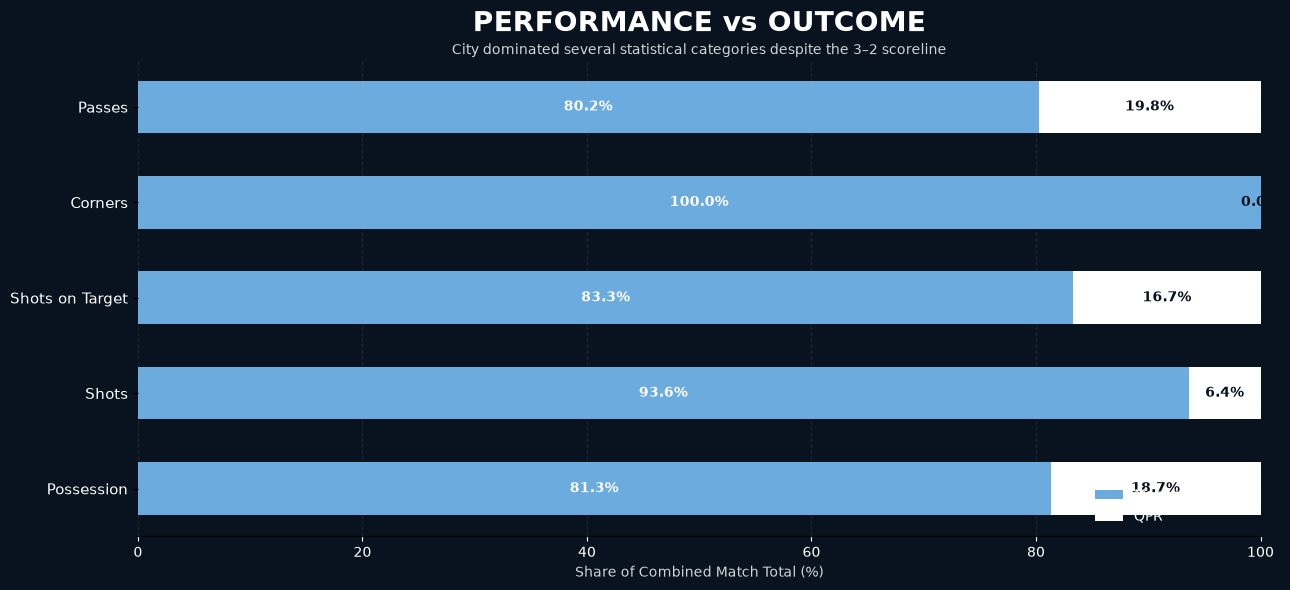

In [19]:
# ============================================
# STEP 12 — PERFORMANCE VS OUTCOME
# ============================================

# Metrics for analysis
metrics = [
    "Possession",
    "Shots",
    "Shots on Target",
    "Corners",
    "Passes"
]

city_values = []
qpr_values = []

for metric in metrics:

    city_value = match_stats.loc[
        match_stats["Metric"] == metric,
        "Manchester City"
    ].iloc[0]

    qpr_value = match_stats.loc[
        match_stats["Metric"] == metric,
        "Queens Park Rangers"
    ].iloc[0]

    city_values.append(city_value)
    qpr_values.append(qpr_value)


# ============================================
# NORMALIZE EACH METRIC
# ============================================

# Convert each metric into percentage of
# the combined City + QPR value.

city_percentages = []
qpr_percentages = []

for city, qpr in zip(city_values, qpr_values):

    total = city + qpr

    city_percentages.append(
        (city / total) * 100
    )

    qpr_percentages.append(
        (qpr / total) * 100
    )


# ============================================
# CREATE CHART
# ============================================

fig, ax = plt.subplots(
    figsize=(13, 6)
)

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")


y = np.arange(len(metrics))


# City
ax.barh(
    y,
    city_percentages,
    color=CITY_COLOR,
    height=0.55,
    label="Manchester City"
)


# QPR
ax.barh(
    y,
    qpr_percentages,
    left=city_percentages,
    color=QPR_COLOR,
    height=0.55,
    label="QPR"
)


# ============================================
# LABELS
# ============================================

for i in range(len(metrics)):

    ax.text(
        city_percentages[i] / 2,
        i,
        f"{city_percentages[i]:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=10
    )

    ax.text(
        city_percentages[i] +
        qpr_percentages[i] / 2,
        i,
        f"{qpr_percentages[i]:.1f}%",
        ha="center",
        va="center",
        color="#08131F",
        fontweight="bold",
        fontsize=10
    )


# ============================================
# AXIS
# ============================================

ax.set_yticks(y)

ax.set_yticklabels(
    metrics,
    color="white",
    fontsize=11
)

ax.set_xlim(0, 100)

ax.set_xlabel(
    "Share of Combined Match Total (%)",
    color="lightgray"
)


# ============================================
# TITLE
# ============================================

ax.set_title(
    "PERFORMANCE vs OUTCOME",
    color="white",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "City dominated several statistical categories despite the 3–2 scoreline",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)


# ============================================
# FORMATTING
# ============================================

ax.tick_params(
    axis="x",
    colors="white"
)

ax.grid(
    axis="x",
    alpha=0.12,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)


ax.legend(
    loc="lower right",
    facecolor="#102233",
    labelcolor="white",
    frameon=False
)

plt.tight_layout()

plt.show()

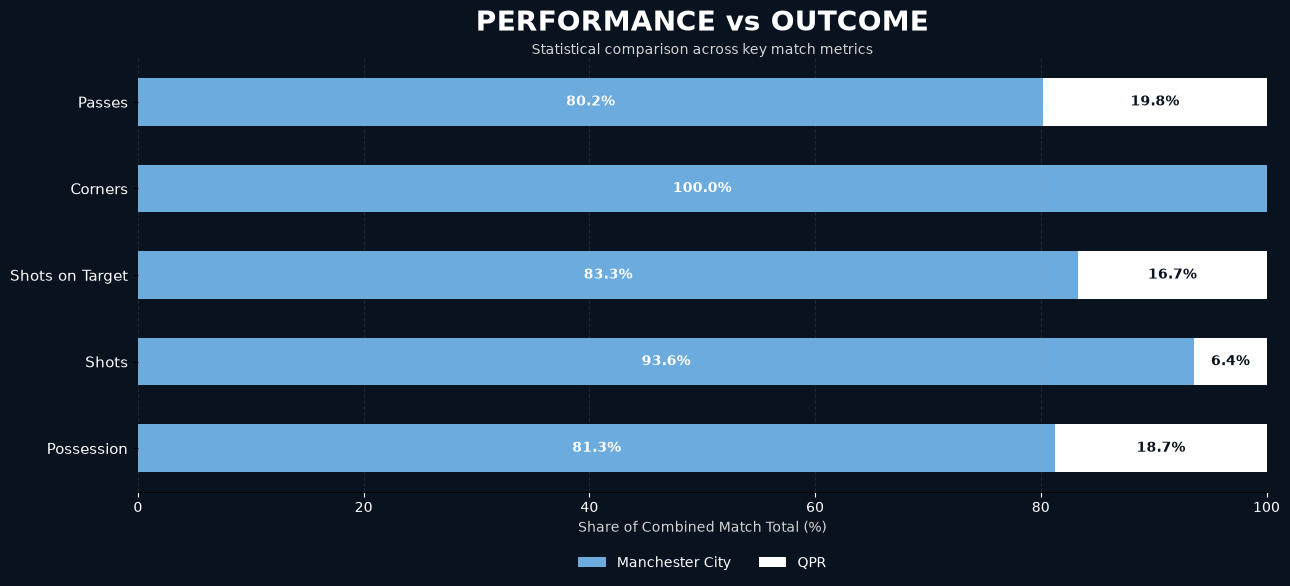

In [20]:
# ============================================
# STEP 12 — PERFORMANCE vs OUTCOME
# ============================================

metrics = [
    "Possession",
    "Shots",
    "Shots on Target",
    "Corners",
    "Passes"
]

city_values = []
qpr_values = []

for metric in metrics:

    city_value = match_stats.loc[
        match_stats["Metric"] == metric,
        "Manchester City"
    ].iloc[0]

    qpr_value = match_stats.loc[
        match_stats["Metric"] == metric,
        "Queens Park Rangers"
    ].iloc[0]

    city_values.append(city_value)
    qpr_values.append(qpr_value)


# ============================================
# NORMALIZE EACH METRIC
# ============================================

city_percentages = []
qpr_percentages = []

for city, qpr in zip(city_values, qpr_values):

    total = city + qpr

    city_percentages.append(
        (city / total) * 100
    )

    qpr_percentages.append(
        (qpr / total) * 100
    )


# ============================================
# CREATE FIGURE
# ============================================

fig, ax = plt.subplots(figsize=(13, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")


y = np.arange(len(metrics))


# ============================================
# BARS
# ============================================

ax.barh(
    y,
    city_percentages,
    color=CITY_COLOR,
    height=0.55,
    label="Manchester City"
)

ax.barh(
    y,
    qpr_percentages,
    left=city_percentages,
    color=QPR_COLOR,
    height=0.55,
    label="QPR"
)


# ============================================
# PERCENTAGE LABELS
# ============================================

for i in range(len(metrics)):

    # City percentage
    ax.text(
        city_percentages[i] / 2,
        i,
        f"{city_percentages[i]:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=10
    )

    # QPR percentage
    if qpr_percentages[i] > 5:

        ax.text(
            city_percentages[i] +
            qpr_percentages[i] / 2,
            i,
            f"{qpr_percentages[i]:.1f}%",
            ha="center",
            va="center",
            color="#08131F",
            fontweight="bold",
            fontsize=10
        )


# ============================================
# AXIS
# ============================================

ax.set_yticks(y)

ax.set_yticklabels(
    metrics,
    color="white",
    fontsize=11
)

ax.set_xlim(0, 100)

ax.set_xlabel(
    "Share of Combined Match Total (%)",
    color="lightgray",
    fontsize=10
)


# ============================================
# TITLE
# ============================================

ax.set_title(
    "PERFORMANCE vs OUTCOME",
    color="white",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Statistical comparison across key match metrics",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)


# ============================================
# FORMATTING
# ============================================

ax.tick_params(
    axis="x",
    colors="white"
)

ax.grid(
    axis="x",
    alpha=0.12,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)


# Put legend above chart
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    facecolor="#102233",
    labelcolor="white",
    frameon=False
)

plt.tight_layout()

plt.show()

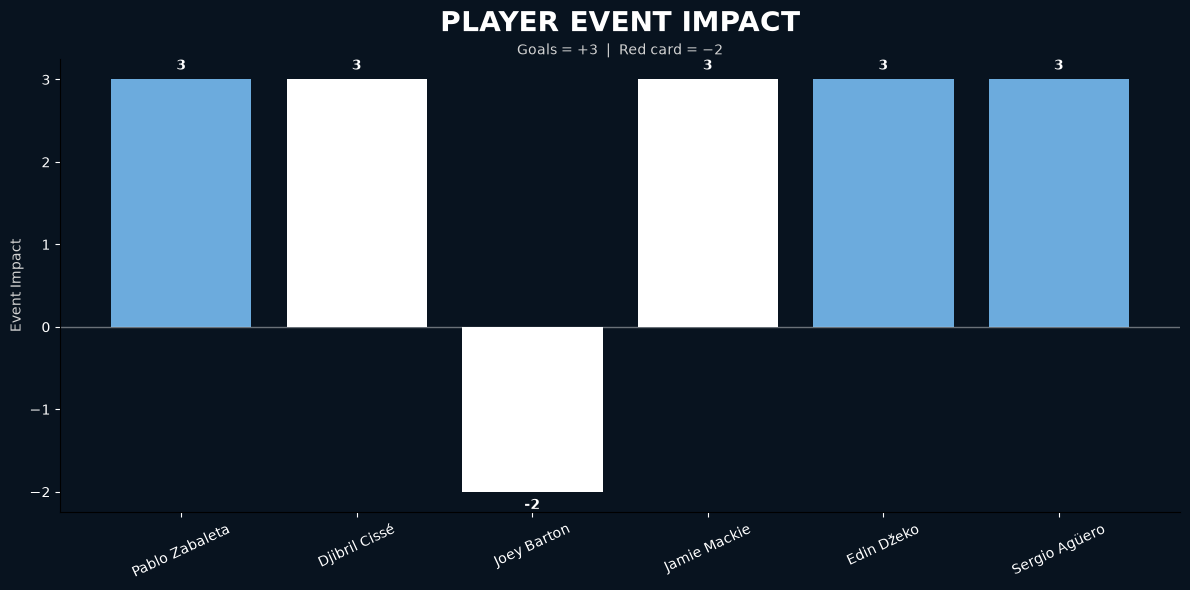

In [21]:
# ============================================
# STEP 13 — PLAYER EVENT IMPACT
# ============================================

player_events = events.copy()

# Give each event an impact value
impact_values = []

for _, row in player_events.iterrows():

    if row["event"] == "Goal":
        impact_values.append(3)

    elif row["event"] == "Red Card":
        impact_values.append(-2)

    else:
        impact_values.append(0)


player_events["impact"] = impact_values


# ============================================
# CREATE FIGURE
# ============================================

fig, ax = plt.subplots(figsize=(12, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")


# Colors
bar_colors = []

for _, row in player_events.iterrows():

    if row["team"] == "Manchester City":
        bar_colors.append(CITY_COLOR)
    else:
        bar_colors.append(QPR_COLOR)


# Bars
bars = ax.bar(
    player_events["player"],
    player_events["impact"],
    color=bar_colors
)


# ============================================
# VALUE LABELS
# ============================================

for bar, value in zip(bars, player_events["impact"]):

    if value >= 0:
        y_position = value + 0.08
        vertical = "bottom"
    else:
        y_position = value - 0.08
        vertical = "top"

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        y_position,
        str(value),
        ha="center",
        va=vertical,
        color="white",
        fontweight="bold"
    )


# ============================================
# TITLE
# ============================================

ax.set_title(
    "PLAYER EVENT IMPACT",
    color="white",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Goals = +3  |  Red card = −2",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)


# ============================================
# AXIS
# ============================================

ax.axhline(
    0,
    color="white",
    linewidth=1,
    alpha=0.4
)

ax.set_ylabel(
    "Event Impact",
    color="lightgray"
)

ax.tick_params(
    axis="x",
    colors="white",
    rotation=25
)

ax.tick_params(
    axis="y",
    colors="white"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()

In [22]:
# ==========================================
# CREATE PROJECT DATA FOLDERS
# ==========================================

import os

os.makedirs("../data/raw", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

print("Data folders created successfully! ✅")

Data folders created successfully! ✅


In [23]:
# ==========================================
# CREATE CITY vs QPR EVENTS DATASET
# ==========================================

events_data = pd.DataFrame({
    "minute": [39, 48, 55, 66, 92, 94],
    
    "minute_display": [
        "39'",
        "48'",
        "55'",
        "66'",
        "90+2'",
        "90+4'"
    ],
    
    "team": [
        "Manchester City",
        "Queens Park Rangers",
        "Queens Park Rangers",
        "Queens Park Rangers",
        "Manchester City",
        "Manchester City"
    ],
    
    "player": [
        "Pablo Zabaleta",
        "Djibril Cissé",
        "Joey Barton",
        "Jamie Mackie",
        "Edin Džeko",
        "Sergio Agüero"
    ],
    
    "event": [
        "Goal",
        "Goal",
        "Red Card",
        "Goal",
        "Goal",
        "Goal"
    ],
    
    "score_after": [
        "1-0",
        "1-1",
        "1-1",
        "1-2",
        "2-2",
        "3-2"
    ]
})

# Save the dataset
events_data.to_csv(
    "../data/raw/city_qpr_events.csv",
    index=False
)

print("Events dataset created successfully! ✅")
print()
print(f"Rows: {len(events_data)}")
print(f"Columns: {len(events_data.columns)}")
print()
print(events_data)

Events dataset created successfully! ✅

Rows: 6
Columns: 6

   minute minute_display                 team          player     event  \
0      39            39'      Manchester City  Pablo Zabaleta      Goal   
1      48            48'  Queens Park Rangers   Djibril Cissé      Goal   
2      55            55'  Queens Park Rangers     Joey Barton  Red Card   
3      66            66'  Queens Park Rangers    Jamie Mackie      Goal   
4      92          90+2'      Manchester City      Edin Džeko      Goal   
5      94          90+4'      Manchester City   Sergio Agüero      Goal   

  score_after  
0         1-0  
1         1-1  
2         1-1  
3         1-2  
4         2-2  
5         3-2  


In [24]:
# ==========================================
# CREATE CITY vs QPR MATCH STATISTICS DATASET
# ==========================================

match_stats_data = pd.DataFrame({
    "metric": [
        "Possession",
        "Shots",
        "Shots on Target",
        "Corners",
        "Passes",
        "Pass Accuracy",
        "Yellow Cards",
        "Red Cards"
    ],

    "Manchester City": [
        81.3,
        44,
        15,
        19,
        710,
        91.7,
        1,
        0
    ],

    "Queens Park Rangers": [
        18.7,
        3,
        3,
        0,
        175,
        49.7,
        1,
        1
    ]
})

# Save as CSV
match_stats_data.to_csv(
    "../data/raw/city_qpr_match_stats.csv",
    index=False
)

print("Match statistics dataset created successfully! ✅")
print()
print(f"Rows: {len(match_stats_data)}")
print(f"Columns: {len(match_stats_data.columns)}")
print()
print(match_stats_data)

Match statistics dataset created successfully! ✅

Rows: 8
Columns: 3

            metric  Manchester City  Queens Park Rangers
0       Possession             81.3                 18.7
1            Shots             44.0                  3.0
2  Shots on Target             15.0                  3.0
3          Corners             19.0                  0.0
4           Passes            710.0                175.0
5    Pass Accuracy             91.7                 49.7
6     Yellow Cards              1.0                  1.0
7        Red Cards              0.0                  1.0


In [25]:
# ==========================================
# LOAD PROJECT DATA FROM CSV FILES
# ==========================================

events = pd.read_csv("../data/raw/city_qpr_events.csv")
match_stats = pd.read_csv("../data/raw/city_qpr_match_stats.csv")

# Keep column names compatible with our earlier analysis code
events["score"] = events["score_after"]

match_stats = match_stats.rename(
    columns={"metric": "Metric"}
)

print("CSV data loaded successfully! ✅")
print()

print("EVENT DATA")
print(events)

print()
print("MATCH STATISTICS")
print(match_stats)

CSV data loaded successfully! ✅

EVENT DATA
   minute minute_display                 team          player     event  \
0      39            39'      Manchester City  Pablo Zabaleta      Goal   
1      48            48'  Queens Park Rangers   Djibril Cissé      Goal   
2      55            55'  Queens Park Rangers     Joey Barton  Red Card   
3      66            66'  Queens Park Rangers    Jamie Mackie      Goal   
4      92          90+2'      Manchester City      Edin Džeko      Goal   
5      94          90+4'      Manchester City   Sergio Agüero      Goal   

  score_after score  
0         1-0   1-0  
1         1-1   1-1  
2         1-1   1-1  
3         1-2   1-2  
4         2-2   2-2  
5         3-2   3-2  

MATCH STATISTICS
            Metric  Manchester City  Queens Park Rangers
0       Possession             81.3                 18.7
1            Shots             44.0                  3.0
2  Shots on Target             15.0                  3.0
3          Corners            

In [26]:
# ==========================================
# DATA QUALITY CHECK
# ==========================================

print("========== EVENTS DATA ==========")

print("Number of events:", len(events))
print("Missing values:")
print(events.isnull().sum())

print()
print("========== MATCH STATISTICS ==========")

print("Number of metrics:", len(match_stats))
print("Missing values:")
print(match_stats.isnull().sum())

print()
print("========== CHECK COMPLETE ==========")

if events.isnull().sum().sum() == 0 and match_stats.isnull().sum().sum() == 0:
    print("✅ No missing values found!")
else:
    print("⚠️ Missing values detected.")

========== EVENTS DATA ==========
Number of events: 6
Missing values:
minute            0
minute_display    0
team              0
player            0
event             0
score_after       0
score             0
dtype: int64

========== MATCH STATISTICS ==========
Number of metrics: 8
Missing values:
Metric                 0
Manchester City        0
Queens Park Rangers    0
dtype: int64

========== CHECK COMPLETE ==========
✅ No missing values found!


In [27]:
# ==========================================
# CREATE DATA DICTIONARY
# ==========================================

data_dictionary = pd.DataFrame({
    "dataset": [
        "city_qpr_events.csv",
        "city_qpr_events.csv",
        "city_qpr_events.csv",
        "city_qpr_events.csv",
        "city_qpr_events.csv",
        "city_qpr_events.csv",
        "city_qpr_match_stats.csv",
        "city_qpr_match_stats.csv",
        "city_qpr_match_stats.csv"
    ],

    "column": [
        "minute",
        "minute_display",
        "team",
        "player",
        "event",
        "score_after",
        "metric",
        "Manchester City",
        "Queens Park Rangers"
    ],

    "description": [
        "Numeric match minute of the event",
        "Human-readable match minute including stoppage time",
        "Team associated with the event",
        "Player associated with the event",
        "Type of event such as Goal or Red Card",
        "Score immediately after the event",
        "Match statistic being measured",
        "Manchester City's value for the metric",
        "QPR's value for the metric"
    ]
})

data_dictionary.to_csv(
    "../data/data_dictionary.csv",
    index=False
)

print("Data dictionary created successfully! ✅")
print()
print(data_dictionary)

Data dictionary created successfully! ✅

                    dataset               column  \
0       city_qpr_events.csv               minute   
1       city_qpr_events.csv       minute_display   
2       city_qpr_events.csv                 team   
3       city_qpr_events.csv               player   
4       city_qpr_events.csv                event   
5       city_qpr_events.csv          score_after   
6  city_qpr_match_stats.csv               metric   
7  city_qpr_match_stats.csv      Manchester City   
8  city_qpr_match_stats.csv  Queens Park Rangers   

                                         description  
0                  Numeric match minute of the event  
1  Human-readable match minute including stoppage...  
2                     Team associated with the event  
3                   Player associated with the event  
4             Type of event such as Goal or Red Card  
5                  Score immediately after the event  
6                     Match statistic being measured 

In [28]:
# ==========================================
# CREATE PROCESSED EVENT FEATURES
# ==========================================

processed_events = events.copy()

# Identify whether each event is a goal
processed_events["is_goal"] = (
    processed_events["event"] == "Goal"
).astype(int)

# Identify whether each event is a red card
processed_events["is_red_card"] = (
    processed_events["event"] == "Red Card"
).astype(int)

# Calculate whether the event happened in stoppage time
processed_events["is_stoppage_time"] = (
    processed_events["minute"] >= 90
).astype(int)

# Create a simple event category
processed_events["event_category"] = processed_events["event"].map({
    "Goal": "Scoring Event",
    "Red Card": "Disciplinary Event"
})

# Save processed dataset
processed_events.to_csv(
    "../data/processed/city_qpr_events_processed.csv",
    index=False
)

print("Processed dataset created successfully! ✅")
print()
print(processed_events)

Processed dataset created successfully! ✅

   minute minute_display                 team          player     event  \
0      39            39'      Manchester City  Pablo Zabaleta      Goal   
1      48            48'  Queens Park Rangers   Djibril Cissé      Goal   
2      55            55'  Queens Park Rangers     Joey Barton  Red Card   
3      66            66'  Queens Park Rangers    Jamie Mackie      Goal   
4      92          90+2'      Manchester City      Edin Džeko      Goal   
5      94          90+4'      Manchester City   Sergio Agüero      Goal   

  score_after score  is_goal  is_red_card  is_stoppage_time  \
0         1-0   1-0        1            0                 0   
1         1-1   1-1        1            0                 0   
2         1-1   1-1        0            1                 0   
3         1-2   1-2        1            0                 0   
4         2-2   2-2        1            0                 1   
5         3-2   3-2        1            0            

In [29]:
# ==========================================
# EVENT INTENSITY ANALYSIS
# ==========================================

# Count events by team
event_counts = (
    processed_events
    .groupby(["team", "event"])
    .size()
    .reset_index(name="count")
)

print("EVENT COUNTS")
print(event_counts)

# Count Manchester City's scoring events
city_goals = processed_events[
    (processed_events["team"] == "Manchester City") &
    (processed_events["is_goal"] == 1)
]

# Count QPR scoring events
qpr_goals = processed_events[
    (processed_events["team"] == "Queens Park Rangers") &
    (processed_events["is_goal"] == 1)
]

# Stoppage-time events
stoppage_events = processed_events[
    processed_events["is_stoppage_time"] == 1
]

print()
print("MANCHESTER CITY GOALS:", len(city_goals))
print("QPR GOALS:", len(qpr_goals))
print("STOPPAGE-TIME EVENTS:", len(stoppage_events))

print()
print("SToppage-time events:")
print(
    stoppage_events[
        ["minute_display", "team", "player", "event", "score_after"]
    ]
)

EVENT COUNTS
                  team     event  count
0      Manchester City      Goal      3
1  Queens Park Rangers      Goal      2
2  Queens Park Rangers  Red Card      1

MANCHESTER CITY GOALS: 3
QPR GOALS: 2
STOPPAGE-TIME EVENTS: 2

SToppage-time events:
  minute_display             team         player event score_after
4          90+2'  Manchester City     Edin Džeko  Goal         2-2
5          90+4'  Manchester City  Sergio Agüero  Goal         3-2


In [30]:
# ==========================================
# MATCH EVENT GAP ANALYSIS
# ==========================================

# Make a copy and calculate time between events
event_gap = processed_events.copy()

event_gap["minutes_since_previous_event"] = (
    event_gap["minute"].diff()
)

# First event has no previous event
event_gap["minutes_since_previous_event"] = (
    event_gap["minutes_since_previous_event"]
    .fillna(0)
)

# Calculate whether the event changed the score
event_gap["score_changed"] = (
    event_gap["event"] == "Goal"
).astype(int)

# Display the analysis
event_gap_analysis = event_gap[
    [
        "minute_display",
        "team",
        "player",
        "event",
        "score_after",
        "minutes_since_previous_event",
        "score_changed"
    ]
]

print("========== MATCH EVENT GAP ANALYSIS ==========")
print(event_gap_analysis)

print()
print("========== LATE MATCH ANALYSIS ==========")

late_events = event_gap[
    event_gap["minute"] >= 90
]

print(late_events[
    [
        "minute_display",
        "player",
        "event",
        "score_after",
        "minutes_since_previous_event"
    ]
])

========== MATCH EVENT GAP ANALYSIS ==========
  minute_display                 team          player     event score_after  \
0            39'      Manchester City  Pablo Zabaleta      Goal         1-0   
1            48'  Queens Park Rangers   Djibril Cissé      Goal         1-1   
2            55'  Queens Park Rangers     Joey Barton  Red Card         1-1   
3            66'  Queens Park Rangers    Jamie Mackie      Goal         1-2   
4          90+2'      Manchester City      Edin Džeko      Goal         2-2   
5          90+4'      Manchester City   Sergio Agüero      Goal         3-2   

   minutes_since_previous_event  score_changed  
0                           0.0              1  
1                           9.0              1  
2                           7.0              0  
3                          11.0              1  
4                          26.0              1  
5                           2.0              1  

========== LATE MATCH ANALYSIS ==========
  minute_disp

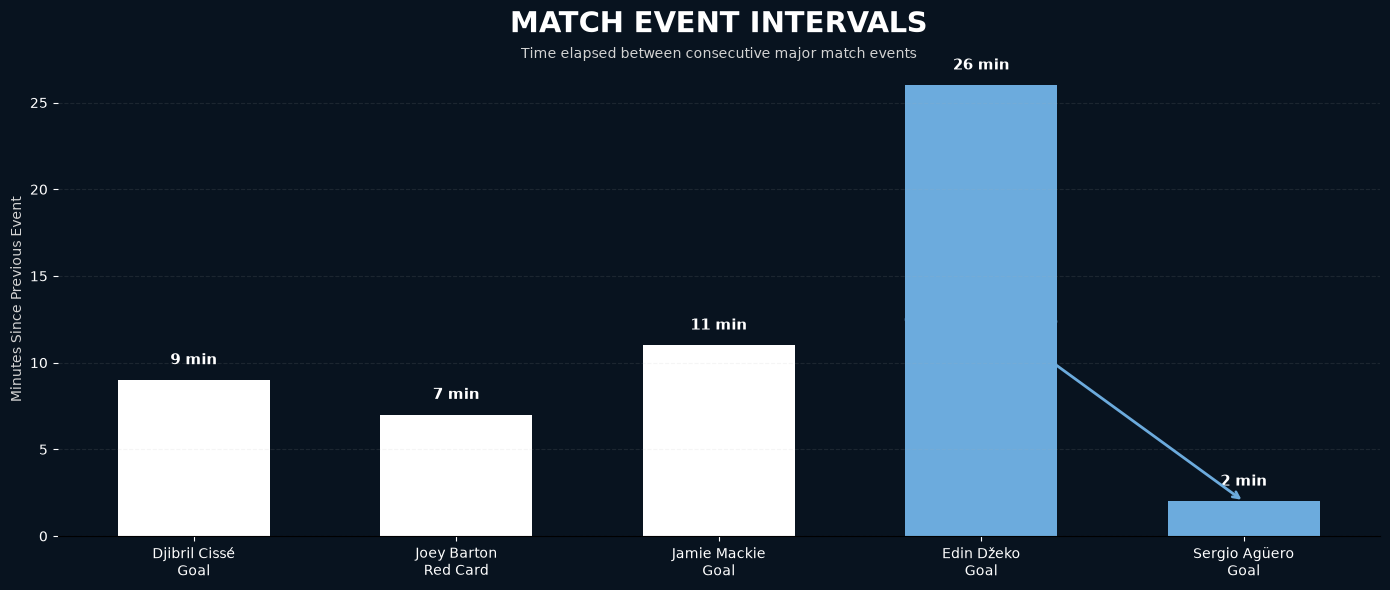

In [33]:
# ==========================================
# MATCH EVENT GAP VISUALIZATION — POLISHED
# ==========================================

gap_data = event_gap.iloc[1:].copy()

gap_data["label"] = (
    gap_data["player"]
    + "\n"
    + gap_data["event"]
)

fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Bar colors
bar_colors = [
    CITY_COLOR if team == "Manchester City" else QPR_COLOR
    for team in gap_data["team"]
]

bars = ax.bar(
    gap_data["label"],
    gap_data["minutes_since_previous_event"],
    color=bar_colors,
    width=0.58
)

# Values above bars
for bar, value in zip(
    bars,
    gap_data["minutes_since_previous_event"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{value:.0f} min",
        ha="center",
        va="bottom",
        color="white",
        fontweight="bold",
        fontsize=11
    )

# Highlight the final 2-minute interval
final_gap_index = len(gap_data) - 1
final_gap_value = gap_data["minutes_since_previous_event"].iloc[-1]

ax.annotate(
    "DŽEKO → AGÜERO\nONLY ~2 MINUTES",
    xy=(final_gap_index, final_gap_value),
    xytext=(final_gap_index - 1.0, 13),
    ha="center",
    va="center",
    color=CITY_COLOR,
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=2
    )
)

# Title
ax.set_title(
    "MATCH EVENT INTERVALS",
    color="white",
    fontsize=21,
    fontweight="bold",
    pad=22
)

ax.text(
    0.5,
    1.01,
    "Time elapsed between consecutive major match events",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)

# Axis labels
ax.set_ylabel(
    "Minutes Since Previous Event",
    color="lightgray",
    fontsize=10
)

ax.tick_params(
    axis="x",
    colors="white",
    labelsize=10
)

ax.tick_params(
    axis="y",
    colors="white"
)

# Grid
ax.grid(
    axis="y",
    alpha=0.12,
    linestyle="--"
)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [34]:
# ==========================================
# CREATE SHOT PRESSURE DATASET
# ==========================================

shot_pressure_data = pd.DataFrame({
    "metric": [
        "Total City Shots",
        "Total QPR Shots",
        "City Second-Half Shots",
        "City Shots After QPR Final Shot",
        "QPR Final Shot Minute"
    ],

    "value": [
        44,
        3,
        34,
        23,
        65.13
    ],

    "unit": [
        "shots",
        "shots",
        "shots",
        "shots",
        "minute"
    ],

    "source": [
        "Opta Analyst",
        "Match statistics",
        "Opta Analyst",
        "Opta Analyst",
        "Opta Analyst"
    ]
})

shot_pressure_data.to_csv(
    "../data/processed/city_qpr_shot_pressure.csv",
    index=False
)

print("Shot pressure dataset created successfully! ✅")
print()
print(shot_pressure_data)

Shot pressure dataset created successfully! ✅

                            metric  value    unit            source
0                 Total City Shots  44.00   shots      Opta Analyst
1                  Total QPR Shots   3.00   shots  Match statistics
2           City Second-Half Shots  34.00   shots      Opta Analyst
3  City Shots After QPR Final Shot  23.00   shots      Opta Analyst
4            QPR Final Shot Minute  65.13  minute      Opta Analyst


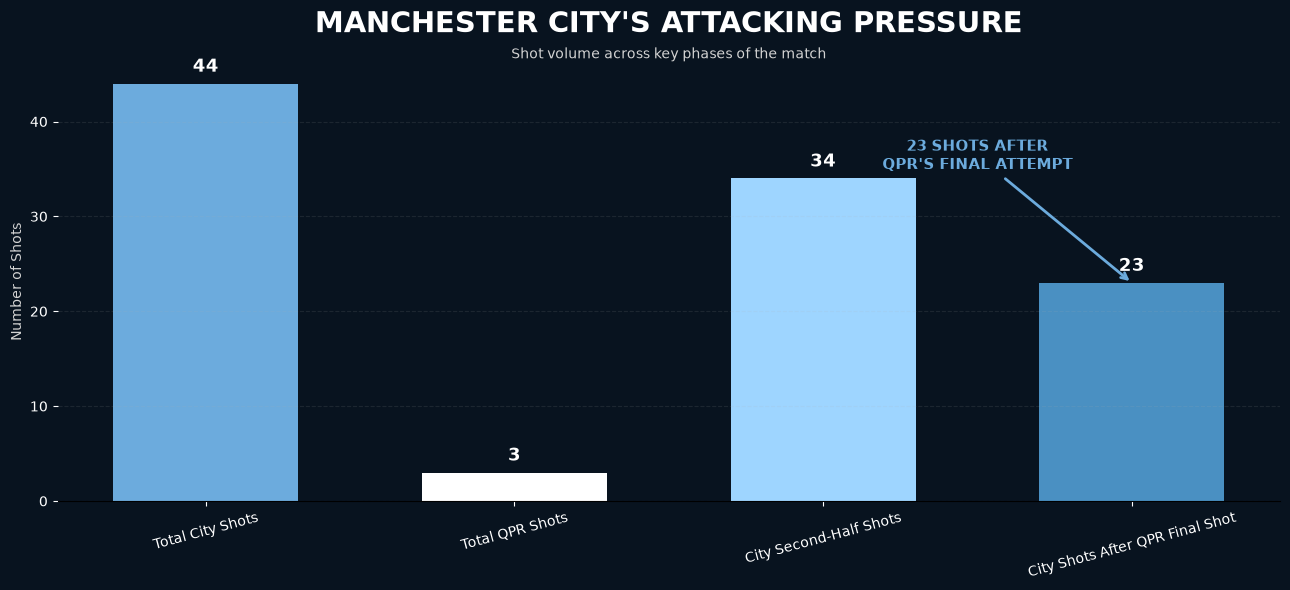

In [35]:
# ==========================================
# SHOT PRESSURE PROFILE
# ==========================================

# Load the processed shot-pressure dataset
shot_data = pd.read_csv(
    "../data/processed/city_qpr_shot_pressure.csv"
)

# Select only shot-count metrics
plot_data = shot_data[
    shot_data["unit"] == "shots"
].copy()

fig, ax = plt.subplots(figsize=(13, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Colors based on the metric
bar_colors = [
    CITY_COLOR,
    QPR_COLOR,
    "#9ED5FF",
    "#4A90C2"
]

bars = ax.bar(
    plot_data["metric"],
    plot_data["value"],
    color=bar_colors,
    width=0.6
)

# Values above bars
for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.8,
        f"{value:.0f}",
        ha="center",
        va="bottom",
        color="white",
        fontsize=13,
        fontweight="bold"
    )

# Highlight City's 23 shots after QPR's final attempt
ax.annotate(
    "23 SHOTS AFTER\nQPR'S FINAL ATTEMPT",
    xy=(3, 23),
    xytext=(2.5, 35),
    ha="center",
    color=CITY_COLOR,
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=2
    )
)

# Titles
ax.set_title(
    "MANCHESTER CITY'S ATTACKING PRESSURE",
    color="white",
    fontsize=21,
    fontweight="bold",
    pad=22
)

ax.text(
    0.5,
    1.01,
    "Shot volume across key phases of the match",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)

# Axis
ax.set_ylabel(
    "Number of Shots",
    color="lightgray",
    fontsize=10
)

ax.tick_params(
    axis="x",
    colors="white",
    labelsize=10,
    rotation=15
)

ax.tick_params(
    axis="y",
    colors="white"
)

ax.grid(
    axis="y",
    alpha=0.12,
    linestyle="--"
)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

In [36]:
# ==========================================
# ATTACKING EFFICIENCY ANALYSIS
# ==========================================

# Match values
city_goals = 3
qpr_goals = 2

city_shots = match_stats.loc[
    match_stats["Metric"] == "Shots",
    "Manchester City"
].iloc[0]

qpr_shots = match_stats.loc[
    match_stats["Metric"] == "Shots",
    "Queens Park Rangers"
].iloc[0]

city_sot = match_stats.loc[
    match_stats["Metric"] == "Shots on Target",
    "Manchester City"
].iloc[0]

qpr_sot = match_stats.loc[
    match_stats["Metric"] == "Shots on Target",
    "Queens Park Rangers"
].iloc[0]


# Calculate efficiency metrics
efficiency_data = pd.DataFrame({
    "metric": [
        "Shot Conversion",
        "Shots on Target Rate",
        "Goal Rate from Shots on Target"
    ],

    "Manchester City": [
        (city_goals / city_shots) * 100,
        (city_sot / city_shots) * 100,
        (city_goals / city_sot) * 100
    ],

    "Queens Park Rangers": [
        (qpr_goals / qpr_shots) * 100,
        (qpr_sot / qpr_shots) * 100,
        (qpr_goals / qpr_sot) * 100
    ]
})


# Save processed efficiency dataset
efficiency_data.to_csv(
    "../data/processed/city_qpr_attacking_efficiency.csv",
    index=False
)


print("Attacking efficiency dataset created successfully! ✅")
print()

print(
    efficiency_data.round(1)
)

Attacking efficiency dataset created successfully! ✅

                           metric  Manchester City  Queens Park Rangers
0                 Shot Conversion              6.8                 66.7
1            Shots on Target Rate             34.1                100.0
2  Goal Rate from Shots on Target             20.0                 66.7


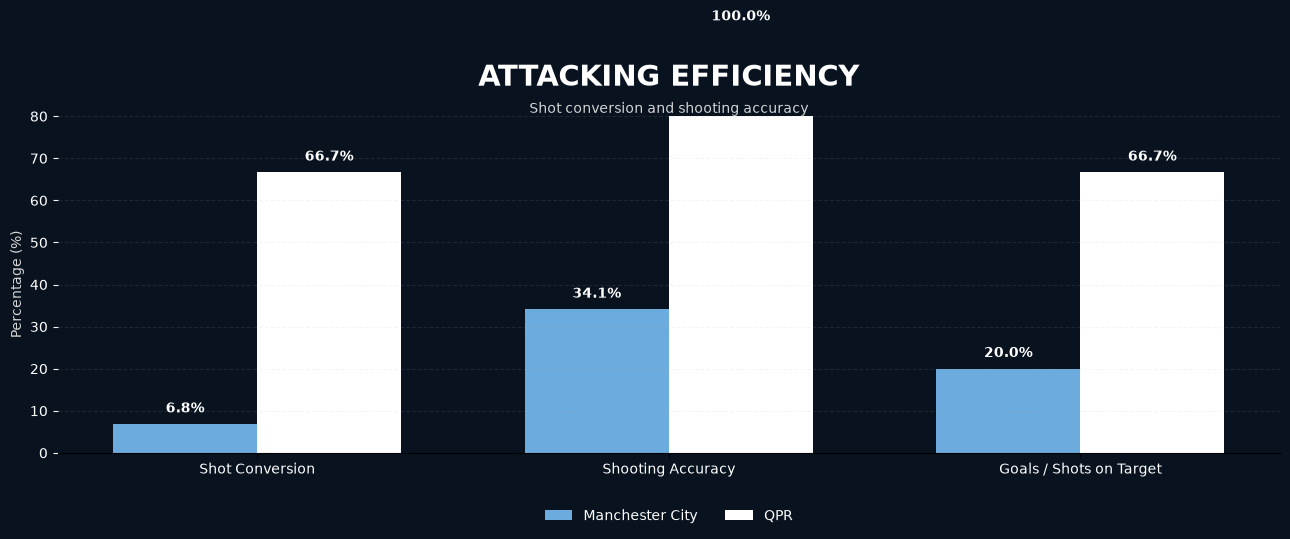

In [37]:
# ==========================================
# ATTACKING EFFICIENCY COMPARISON
# ==========================================

efficiency_plot = pd.read_csv(
    "../data/processed/city_qpr_attacking_efficiency.csv"
)

metrics = efficiency_plot["metric"]

city_values = efficiency_plot["Manchester City"]
qpr_values = efficiency_plot["Queens Park Rangers"]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))

fig.patch.set_facecolor("#08131F")
ax.set_facecolor("#08131F")

# Bars
city_bars = ax.bar(
    x - width / 2,
    city_values,
    width,
    label="Manchester City",
    color=CITY_COLOR
)

qpr_bars = ax.bar(
    x + width / 2,
    qpr_values,
    width,
    label="QPR",
    color=QPR_COLOR
)

# Add percentage labels
for bars in [city_bars, qpr_bars]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 2,
            f"{value:.1f}%",
            ha="center",
            va="bottom",
            color="white",
            fontsize=10,
            fontweight="bold"
        )

# Title
ax.set_title(
    "ATTACKING EFFICIENCY",
    color="white",
    fontsize=21,
    fontweight="bold",
    pad=22
)

ax.text(
    0.5,
    1.01,
    "Shot conversion and shooting accuracy",
    transform=ax.transAxes,
    ha="center",
    color="lightgray",
    fontsize=10
)

# Axis
ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Shot Conversion",
        "Shooting Accuracy",
        "Goals / Shots on Target"
    ],
    color="white",
    fontsize=10
)

ax.set_ylabel(
    "Percentage (%)",
    color="lightgray"
)

ax.set_ylim(0, 80)

ax.tick_params(
    axis="y",
    colors="white"
)

ax.grid(
    axis="y",
    alpha=0.12,
    linestyle="--"
)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    facecolor="#102233",
    labelcolor="white",
    frameon=False
)

plt.tight_layout()
plt.show()

In [38]:
# ==========================================
# MATCH INTELLIGENCE SUMMARY
# ==========================================

# Core match values
city_shots = int(
    match_stats.loc[
        match_stats["Metric"] == "Shots",
        "Manchester City"
    ].iloc[0]
)

qpr_shots = int(
    match_stats.loc[
        match_stats["Metric"] == "Shots",
        "Queens Park Rangers"
    ].iloc[0]
)

city_sot = int(
    match_stats.loc[
        match_stats["Metric"] == "Shots on Target",
        "Manchester City"
    ].iloc[0]
)

qpr_sot = int(
    match_stats.loc[
        match_stats["Metric"] == "Shots on Target",
        "Queens Park Rangers"
    ].iloc[0]
)

city_possession = float(
    match_stats.loc[
        match_stats["Metric"] == "Possession",
        "Manchester City"
    ].iloc[0]
)

qpr_possession = float(
    match_stats.loc[
        match_stats["Metric"] == "Possession",
        "Queens Park Rangers"
    ].iloc[0]
)


# Derived metrics
shot_difference = city_shots - qpr_shots

city_shot_share = (
    city_shots / (city_shots + qpr_shots)
) * 100

city_sot_rate = (
    city_sot / city_shots
) * 100

late_goal_gap = (
    events.loc[events["event"] == "Goal", "minute"]
    .iloc[-1]
    -
    events.loc[events["event"] == "Goal", "minute"]
    .iloc[-2]
)


# Build intelligence summary
intelligence_summary = pd.DataFrame({
    "Insight": [
        "Final Score",
        "City Shot Advantage",
        "City Shot Share",
        "City Shooting Accuracy",
        "City Possession",
        "QPR Possession",
        "City Second-Half Shots",
        "City Shots After QPR Final Attempt",
        "Final Two Goal Interval"
    ],

    "Value": [
        "3 - 2",
        f"+{shot_difference} shots",
        f"{city_shot_share:.1f}%",
        f"{city_sot_rate:.1f}%",
        f"{city_possession:.1f}%",
        f"{qpr_possession:.1f}%",
        "34",
        "23",
        f"{late_goal_gap} minutes"
    ]
})


# Save summary
intelligence_summary.to_csv(
    "../data/processed/city_qpr_match_intelligence.csv",
    index=False
)


print("MATCH INTELLIGENCE SUMMARY")
print("=" * 45)
print(intelligence_summary.to_string(index=False))

print()
print("Match intelligence dataset saved successfully! ✅")

MATCH INTELLIGENCE SUMMARY
                           Insight     Value
                       Final Score     3 - 2
               City Shot Advantage +41 shots
                   City Shot Share     93.6%
            City Shooting Accuracy     34.1%
                   City Possession     81.3%
                    QPR Possession     18.7%
            City Second-Half Shots        34
City Shots After QPR Final Attempt        23
           Final Two Goal Interval 2 minutes

Match intelligence dataset saved successfully! ✅


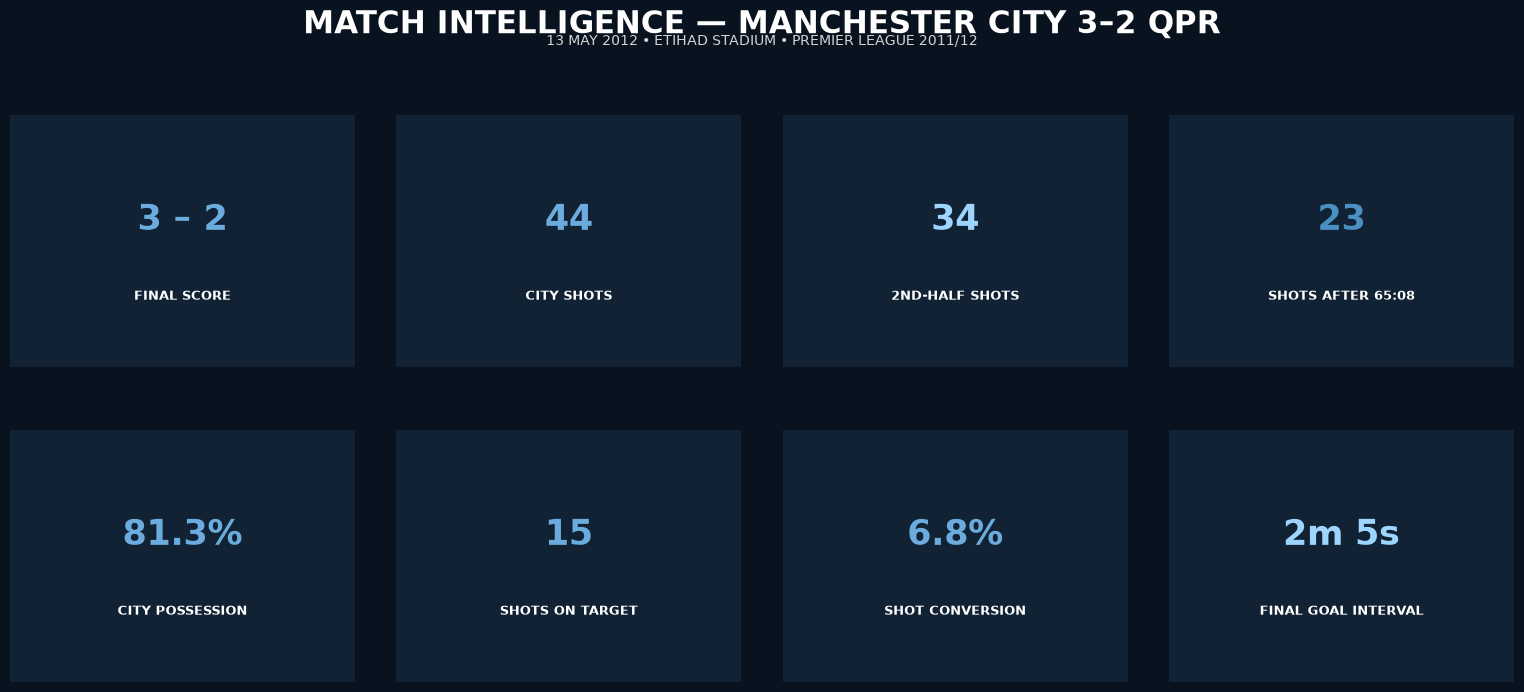

In [39]:
# ==========================================
# MATCH INTELLIGENCE DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

fig.patch.set_facecolor("#08131F")

# Dashboard metrics
dashboard_metrics = [
    ("3 – 2", "FINAL SCORE", CITY_COLOR),
    ("44", "CITY SHOTS", CITY_COLOR),
    ("34", "2ND-HALF SHOTS", "#9ED5FF"),
    ("23", "SHOTS AFTER 65:08", "#4A90C2"),
    ("81.3%", "CITY POSSESSION", CITY_COLOR),
    ("15", "SHOTS ON TARGET", CITY_COLOR),
    ("6.8%", "SHOT CONVERSION", CITY_COLOR),
    ("2m 5s", "FINAL GOAL INTERVAL", "#9ED5FF")
]

for ax, (value, label, accent) in zip(
    axes.flatten(),
    dashboard_metrics
):

    ax.set_facecolor("#102233")

    # Main number
    ax.text(
        0.5,
        0.58,
        value,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=25,
        fontweight="bold",
        color=accent
    )

    # Label
    ax.text(
        0.5,
        0.28,
        label,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="white"
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# Main title
fig.suptitle(
    "MATCH INTELLIGENCE — MANCHESTER CITY 3–2 QPR",
    fontsize=22,
    fontweight="bold",
    color="white",
    y=1.02
)

fig.text(
    0.5,
    0.97,
    "13 MAY 2012 • ETIHAD STADIUM • PREMIER LEAGUE 2011/12",
    ha="center",
    color="lightgray",
    fontsize=10
)

plt.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.87,
    bottom=0.06,
    wspace=0.12,
    hspace=0.25
)

plt.show()

In [46]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

print("Jupyter figure rendering fixed ✅")

Jupyter figure rendering fixed ✅


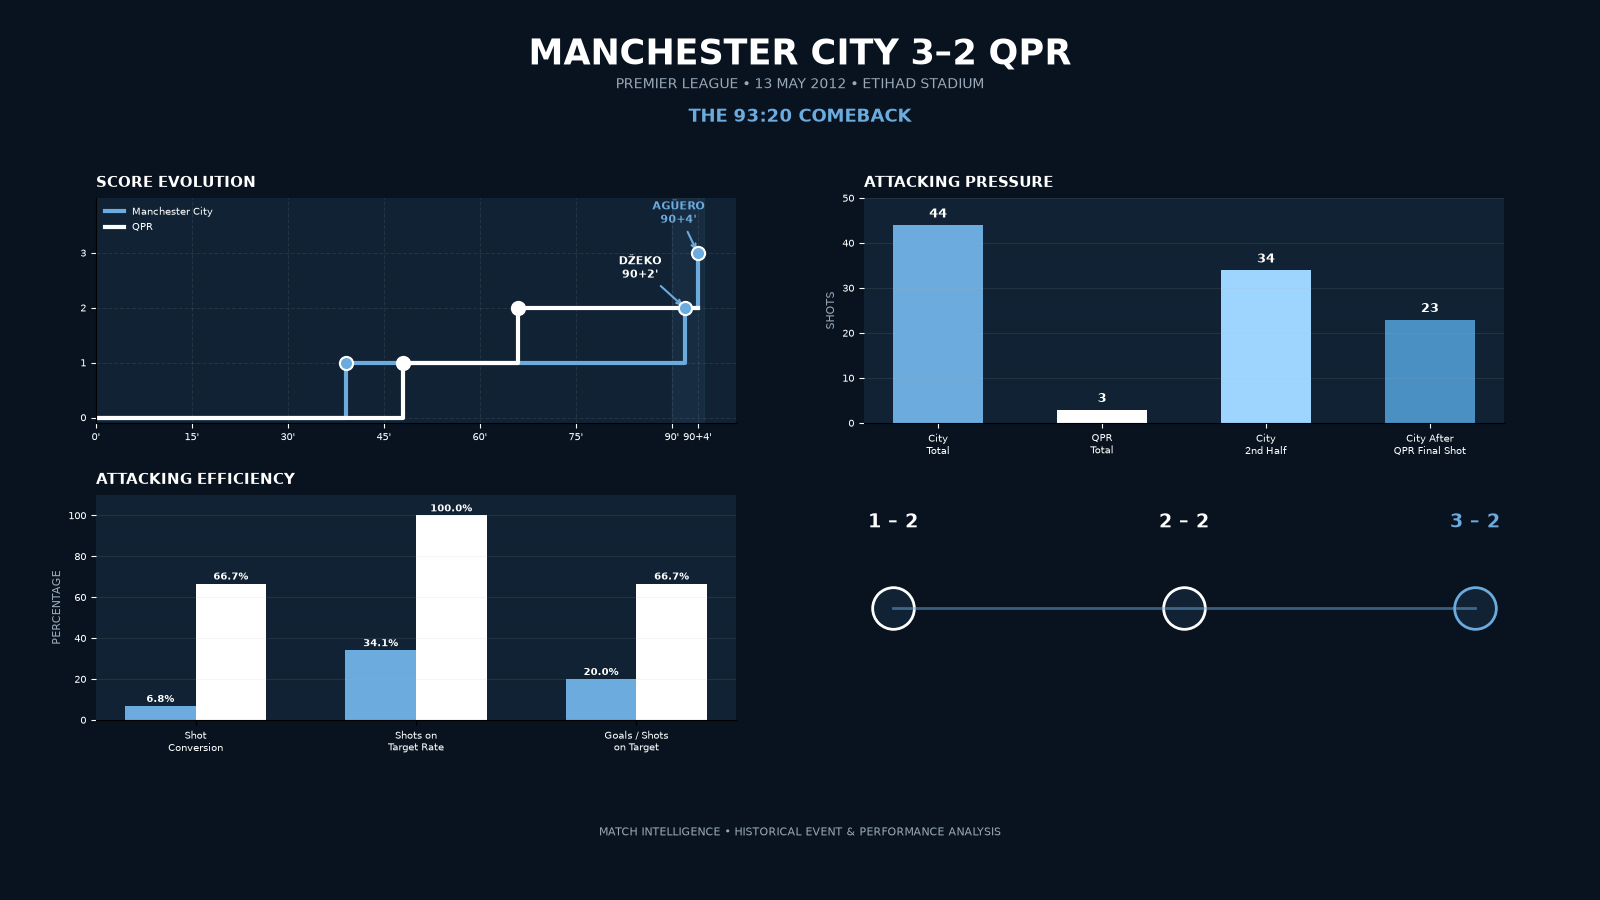

In [47]:
# ============================================================
# FINAL CITY vs QPR — FOOTBALL MATCH INTELLIGENCE DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Close any previous figures
plt.close("all")

# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------
BG = "#08131F"
PANEL = "#102233"
CITY_COLOR = "#6CABDD"
LIGHT_BLUE = "#9ED5FF"
QPR_COLOR = "#FFFFFF"
TEXT = "#FFFFFF"
MUTED = "#9AA9B8"

# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------
fig = plt.figure(figsize=(16, 9), facecolor=BG)

# ------------------------------------------------------------
# HEADER
# ------------------------------------------------------------
header = fig.add_axes([0.05, 0.84, 0.90, 0.12])
header.set_facecolor(BG)
header.axis("off")

header.text(
    0.5, 0.82,
    "MANCHESTER CITY 3–2 QPR",
    ha="center",
    va="center",
    fontsize=25,
    fontweight="bold",
    color=TEXT
)

header.text(
    0.5, 0.55,
    "PREMIER LEAGUE • 13 MAY 2012 • ETIHAD STADIUM",
    ha="center",
    va="center",
    fontsize=10,
    color=MUTED
)

header.text(
    0.5, 0.25,
    "THE 93:20 COMEBACK",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=CITY_COLOR
)

# ------------------------------------------------------------
# SCORE EVOLUTION
# ------------------------------------------------------------
ax1 = fig.add_axes([0.06, 0.53, 0.40, 0.25])
ax1.set_facecolor(PANEL)

minutes = [0, 39, 48, 66, 92, 94]
city_scores = [0, 1, 1, 1, 2, 3]
qpr_scores = [0, 0, 1, 2, 2, 2]

ax1.step(
    minutes,
    city_scores,
    where="post",
    color=CITY_COLOR,
    linewidth=3,
    label="Manchester City"
)

ax1.step(
    minutes,
    qpr_scores,
    where="post",
    color=QPR_COLOR,
    linewidth=3,
    label="QPR"
)

# Goal markers
for _, row in events[events["event"] == "Goal"].iterrows():

    if row["team"] == "Manchester City":
        score_value = int(row["score"].split("-")[0])
        color = CITY_COLOR
    else:
        score_value = int(row["score"].split("-")[1])
        color = QPR_COLOR

    ax1.scatter(
        row["minute"],
        score_value,
        s=90,
        color=color,
        edgecolor="white",
        linewidth=1.5,
        zorder=5
    )

# Late goal annotations
ax1.annotate(
    "DŽEKO\n90+2'",
    xy=(92, 2),
    xytext=(85, 2.55),
    color=TEXT,
    fontsize=8,
    fontweight="bold",
    ha="center",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=1.5
    )
)

ax1.annotate(
    "AGÜERO\n90+4'",
    xy=(94, 3),
    xytext=(91, 3.55),
    color=CITY_COLOR,
    fontsize=8,
    fontweight="bold",
    ha="center",
    arrowprops=dict(
        arrowstyle="->",
        color=CITY_COLOR,
        linewidth=1.5
    )
)

ax1.axvspan(
    90,
    95,
    color=CITY_COLOR,
    alpha=0.08
)

ax1.set_title(
    "SCORE EVOLUTION",
    color=TEXT,
    fontsize=11,
    fontweight="bold",
    loc="left",
    pad=8
)

ax1.set_xlim(0, 100)
ax1.set_ylim(-0.1, 4)

ax1.set_xticks(
    [0, 15, 30, 45, 60, 75, 90, 94]
)

ax1.set_xticklabels(
    ["0'", "15'", "30'", "45'", "60'", "75'", "90'", "90+4'"],
    fontsize=7
)

ax1.set_yticks([0, 1, 2, 3])

ax1.tick_params(
    colors=TEXT,
    labelsize=7
)

ax1.grid(
    alpha=0.12,
    linestyle="--"
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

ax1.legend(
    loc="upper left",
    fontsize=7,
    frameon=False,
    labelcolor=TEXT
)

# ------------------------------------------------------------
# ATTACKING PRESSURE
# ------------------------------------------------------------
ax2 = fig.add_axes([0.54, 0.53, 0.40, 0.25])
ax2.set_facecolor(PANEL)

pressure_labels = [
    "City\nTotal",
    "QPR\nTotal",
    "City\n2nd Half",
    "City After\nQPR Final Shot"
]

pressure_values = [44, 3, 34, 23]

pressure_colors = [
    CITY_COLOR,
    QPR_COLOR,
    LIGHT_BLUE,
    "#4A90C2"
]

bars = ax2.bar(
    pressure_labels,
    pressure_values,
    color=pressure_colors,
    width=0.55
)

for bar, value in zip(bars, pressure_values):

    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        str(value),
        ha="center",
        va="bottom",
        color=TEXT,
        fontsize=9,
        fontweight="bold"
    )

ax2.set_title(
    "ATTACKING PRESSURE",
    color=TEXT,
    fontsize=11,
    fontweight="bold",
    loc="left",
    pad=8
)

ax2.set_ylabel(
    "SHOTS",
    color=MUTED,
    fontsize=8
)

ax2.tick_params(
    colors=TEXT,
    labelsize=7
)

ax2.set_ylim(0, 50)

ax2.grid(
    axis="y",
    alpha=0.12
)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.spines["left"].set_visible(False)

# ------------------------------------------------------------
# ATTACKING EFFICIENCY
# ------------------------------------------------------------
ax3 = fig.add_axes([0.06, 0.20, 0.40, 0.25])
ax3.set_facecolor(PANEL)

efficiency_plot = pd.read_csv(
    "../data/processed/city_qpr_attacking_efficiency.csv"
)

metrics = efficiency_plot["metric"].tolist()

city_values = efficiency_plot[
    "Manchester City"
].tolist()

qpr_values = efficiency_plot[
    "Queens Park Rangers"
].tolist()

x = np.arange(len(metrics))
width = 0.32

bars1 = ax3.bar(
    x - width / 2,
    city_values,
    width,
    color=CITY_COLOR,
    label="Manchester City"
)

bars2 = ax3.bar(
    x + width / 2,
    qpr_values,
    width,
    color=QPR_COLOR,
    label="QPR"
)

for bar in bars1:

    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=7,
        color=TEXT,
        fontweight="bold"
    )

for bar in bars2:

    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=7,
        color=TEXT,
        fontweight="bold"
    )

short_labels = [
    "Shot\nConversion",
    "Shots on\nTarget Rate",
    "Goals / Shots\non Target"
]

ax3.set_xticks(x)
ax3.set_xticklabels(
    short_labels,
    fontsize=7,
    color=TEXT
)

ax3.set_title(
    "ATTACKING EFFICIENCY",
    color=TEXT,
    fontsize=11,
    fontweight="bold",
    loc="left",
    pad=8
)

ax3.set_ylabel(
    "PERCENTAGE",
    color=MUTED,
    fontsize=8
)

ax3.set_ylim(0, 110)

ax3.tick_params(
    axis="y",
    colors=TEXT,
    labelsize=7
)

ax3.grid(
    axis="y",
    alpha=0.12
)

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
ax3.spines["left"].set_visible(False)

# ------------------------------------------------------------
# TURNING POINT
# ------------------------------------------------------------
ax4 = fig.add_axes([0.54, 0.20, 0.40, 0.25])
ax4.set_facecolor(PANEL)
ax4.axis("off")

ax4.text(
    0.5,
    0.90,
    "93:20 TURNING POINT",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=CITY_COLOR
)

ax4.text(
    0.5,
    0.79,
    "CITY TURNED A 1–2 DEFICIT INTO A 3–2 WIN",
    ha="center",
    va="center",
    fontsize=8,
    color=MUTED
)

# Timeline
positions = [0.17, 0.50, 0.83]

# Connecting line
ax4.plot(
    [0.17, 0.83],
    [0.48, 0.48],
    color=CITY_COLOR,
    linewidth=2,
    alpha=0.5
)

turning_points = [
    ("66'", "1 – 2", "MACKIE", TEXT),
    ("90+2'", "2 – 2", "DŽEKO", TEXT),
    ("90+4'", "3 – 2", "AGÜERO", CITY_COLOR)
]

for x_pos, (minute, score, player, color) in zip(
    positions,
    turning_points
):

    ax4.scatter(
        x_pos,
        0.48,
        s=900,
        color=PANEL,
        edgecolor=color,
        linewidth=2
    )

    ax4.text(
        x_pos,
        0.50,
        score,
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold",
        color=color
    )

    ax4.text(
        x_pos,
        0.66,
        minute,
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=color
    )

    ax4.text(
        x_pos,
        0.28,
        player,
        ha="center",
        fontsize=8,
        fontweight="bold",
        color=TEXT
    )

ax4.text(
    0.5,
    0.08,
    "ONLY 125 SECONDS BETWEEN CITY'S FINAL TWO GOALS",
    ha="center",
    fontsize=9,
    fontweight="bold",
    color=CITY_COLOR
)

# ------------------------------------------------------------
# FOOTER
# ------------------------------------------------------------
footer = fig.add_axes([0.05, 0.04, 0.90, 0.07])
footer.set_facecolor(BG)
footer.axis("off")

footer.text(
    0.5,
    0.5,
    "MATCH INTELLIGENCE • HISTORICAL EVENT & PERFORMANCE ANALYSIS",
    ha="center",
    va="center",
    fontsize=8,
    color=MUTED
)

# ------------------------------------------------------------
# SHOW
# ------------------------------------------------------------
plt.show()

In [48]:
import os

print("Your notebook is currently running from:")
print(os.getcwd())

Your notebook is currently running from:
C:\Users\rutuj\Documents\Football_Match_Intelligence\notebooks


In [49]:
import os

current_folder = os.getcwd()

print("Looking for Football_Match_Intelligence...")
print()

for root, dirs, files in os.walk(current_folder):
    if "Football_Match_Intelligence" in dirs:
        project_path = os.path.join(root, "Football_Match_Intelligence")
        print("FOUND:")
        print(project_path)
        break
else:
    print("Not found from the current Jupyter folder.")

Looking for Football_Match_Intelligence...

Not found from the current Jupyter folder.
